# Viviendas iniciadas al año, libres y protegidas

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "viviendas-iniciadas"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Viviendas iniciadas al año, libres y protegidas"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Viviendas"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 0  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Cuántas viviendas empiezan a construirse cada año en España, en total y separadas en libres (de promoción privada, a precio de mercado) y protegidas (con precio o renta limitados por la normativa, de promoción pública o privada), según la estadística del Ministerio de Vivienda y Agenda Urbana que difunde el Banco de España.

**Cómo se lee.** Es un recuento anual: indica cuánta vivienda nueva se pone en marcha, no cuánta se termina (una vivienda tarda en general más de un año en acabarse). El total es la suma de las libres y las protegidas.

**Limitaciones.**
- La serie de viviendas libres empieza más tarde que la de protegidas; antes, el total publicado solo recoge las protegidas, así que el total y las libres de esos años se dejan sin dato (ver notas).
- Las protegidas incluyen las de promoción privada: no son solo vivienda pública. La serie de las de promoción pública está en el notebook `vivienda-protegida-iniciada`.
- La vista España es un total nacional: no distingue dónde se construye. Para eso está la vista por comunidades.
- Solo España: no hay una serie internacional de viviendas iniciadas en las fuentes autorizadas (Eurostat publica permisos de construcción, que son otro concepto, y solo para países europeos).

**Vista por comunidades.** El selector «Por comunidad» de la web muestra, desde 1991, las viviendas iniciadas (libres más protegidas) por cada 1.000 habitantes de cada comunidad y ciudad autónoma, con la de España y sin referencias internacionales. Se divide entre la población para que comunidades de tamaño muy distinto sean comparables. Sale de las tablas por comunidades del Boletín estadístico del Ministerio, las mismas estadísticas que difunde el Banco de España.

## 2. Descarga

Series mensuales del Boletín Estadístico del Banco de España: `D_1KB02000` (viviendas iniciadas, total), `D_1KB02100` (libres) y `D_1KB02200` (protegidas). El fetcher suma los doce meses de cada año completo.

**Vista por comunidades:** Ministerio de Vivienda y Agenda Urbana, Boletín estadístico online, tablas anuales por comunidades autónomas 3.1 (`32200500`, viviendas libres iniciadas) y 1.3 (`31303000`, calificaciones provisionales de vivienda protegida, planes estatales y autonómicos), desde 1991; y, para la población, la serie de cada comunidad de la tabla 56940 del INE (población residente a 1 de enero).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, construir_vista_ccaa, write_grafica_data

from lib import bde, ine, mivau
from lib.tipos import FuenteMeta


def descargar():
    """Devuelve (DataFrame con las series `espana` (total), `libres` y `protegidas`, lista de FuenteMeta)."""
    return bde.get(
        {"D_1KB02000": "espana", "D_1KB02100": "libres", "D_1KB02200": "protegidas"},
        agregacion="suma",
        desde=DESDE,
    )


# Vista por comunidades: filas de las tablas del Ministerio y población a 1 de enero (INE, tabla 56940)
TERRITORIOS_MIVAU = {
    "TOTAL NACIONAL": "espana", "Andalucía": "ES-AN", "Aragón": "ES-AR", "Asturias (Principado de )": "ES-AS",
    "Balears (Illes)": "ES-IB", "Canarias": "ES-CN", "Cantabria": "ES-CB", "Castilla y León": "ES-CL",
    "Castilla-La Mancha": "ES-CM", "Cataluña": "ES-CT", "Comunidad Valenciana": "ES-VC", "Extremadura": "ES-EX",
    "Galicia": "ES-GA", "Madrid (Comunidad de)": "ES-MD", "Murcia (Región de)": "ES-MC",
    "Navarra (Comunidad Foral de)": "ES-NC", "País Vasco": "ES-PV", "Rioja (La)": "ES-RI", "Ceuta": "ES-CE",
    "Melilla": "ES-ML",
}
POBLACION_CCAA = {
    "ECP320": "espana", "ECP115502": "ES-AN", "ECP115501": "ES-AR", "ECP115500": "ES-AS", "ECP115499": "ES-IB",
    "ECP115498": "ES-CN", "ECP115497": "ES-CB", "ECP115496": "ES-CL", "ECP115495": "ES-CM", "ECP115494": "ES-CT",
    "ECP115493": "ES-VC", "ECP115492": "ES-EX", "ECP115491": "ES-GA", "ECP115490": "ES-MD", "ECP115489": "ES-MC",
    "ECP115488": "ES-NC", "ECP115487": "ES-PV", "ECP115486": "ES-RI", "ECP115485": "ES-CE", "ECP115484": "ES-ML",
}


def descargar_ccaa():
    """Viviendas libres iniciadas, calificaciones provisionales de protegidas y población, por comunidad."""
    libres, f_libres = mivau.get("libres_iniciadas", TERRITORIOS_MIVAU, desde=DESDE)
    protegidas, f_protegidas = mivau.get("protegidas_calificaciones", TERRITORIOS_MIVAU, desde=DESDE)
    poblacion, f_pob = ine.get(POBLACION_CCAA, agregacion="primero", desde=DESDE)
    return libres, f_libres, protegidas, f_protegidas, poblacion, f_pob


publicado, fuentes_descarga = descargar()
libres_ccaa, f_libres_ccaa, protegidas_ccaa, f_protegidas_ccaa, poblacion_ccaa, f_pob_ccaa = descargar_ccaa()

## 3. Transformación

El total publicado antes de que empiece la serie de viviendas libres solo contiene vivienda protegida, así que esos años se dejan sin dato en lugar de mostrar un total que no lo es. Las libres y las protegidas van como desglose del total (`desglose`); se comprueba que suman el total publicado.

In [ ]:
ancho = publicado.pivot(index="periodo", columns="serie", values="valor")
INICIO_LIBRES = int(ancho["libres"].first_valid_index())
ancho.loc[ancho.index < INICIO_LIBRES, "espana"] = float("nan")

# Comprobación: libres + protegidas = total publicado (en los años con las tres series)
completos = ancho.dropna()
diferencia = (completos["libres"] + completos["protegidas"] - completos["espana"]).abs().max()
assert diferencia < 1, f"libres + protegidas no suman el total (diferencia máxima {diferencia})"

DESGLOSE = {"libres": "Libres", "protegidas": "Protegidas"}
df = ancho[["espana", *DESGLOSE]].reset_index().melt(id_vars="periodo", var_name="serie", value_name="valor")[["serie", "periodo", "valor"]]
fuentes = fuentes_descarga

NOTAS = [
    "Ministerio de Vivienda y Agenda Urbana, difundido por el Banco de España: viviendas iniciadas, libres y protegidas.",
    f"Antes de {INICIO_LIBRES} el total publicado solo recoge las viviendas protegidas (la serie de viviendas libres empieza ese año), por lo que el total de esos años queda sin dato.",
    "Protegidas: viviendas con precio de venta o renta limitados por la normativa de vivienda protegida, de promoción pública o privada. Libres: el resto.",
    "Serie mensual: se suma cada año natural; el año en curso, incompleto, no se incluye.",
    "Solo España: no hay una serie internacional de viviendas iniciadas en las fuentes autorizadas; Eurostat publica permisos de construcción, que son otro concepto, y solo para países europeos.",
]

# Vista por comunidades: (libres + protegidas) / población a 1 de enero × 1.000. Si falta una de las dos
# (la comunidad no dio el dato), el total de ese año queda sin dato.
l = libres_ccaa.set_index(["serie", "periodo"])["valor"]
p = protegidas_ccaa.set_index(["serie", "periodo"])["valor"]
pob = poblacion_ccaa.set_index(["serie", "periodo"])["valor"]
total_ccaa = (l + p).dropna()
claves = total_ccaa.index.intersection(pob.index)
tasa_ccaa = total_ccaa.loc[claves] / pob.loc[claves] * 1_000
df_ccaa = tasa_ccaa.rename("valor").reset_index()[["serie", "periodo", "valor"]]
assert df_ccaa["valor"].between(0, 60).all(), "viviendas por 1.000 habitantes fuera de rango: ¿unidades?"

# Contraste del total nacional del Ministerio con el del Banco de España (vista España)
contraste = pd.DataFrame({"Ministerio": total_ccaa.loc["espana"], "Banco de España": ancho["espana"]}).dropna()
contraste["diferencia"] = contraste["Ministerio"] - contraste["Banco de España"]
display(contraste)
DISTINTOS = sorted(int(a) for a in contraste.index[contraste["diferencia"].abs() >= 1])

UNIDAD_CCAA = "Viviendas iniciadas por 1.000 habitantes"
de_libres = {f.serie: f for f in f_libres_ccaa}
de_pob = {f.serie: f for f in f_pob_ccaa}
fuentes_ccaa = [
    FuenteMeta(s, mivau.ORGANISMO,
               f"Boletín estadístico online, tablas 32200500 (libres iniciadas) + 31303000 (calificaciones provisionales de protegidas) ÷ INE {de_pob[s].dataset_codigo} (población a 1 de enero) × 1.000",
               de_libres[s].url, de_libres[s].fecha_consulta)
    for s in sorted(set(df_ccaa["serie"]))
]
NOTAS_CCAA = [
    "Viviendas iniciadas por 1.000 habitantes de cada comunidad y ciudad autónoma: viviendas libres iniciadas (tabla 3.1 del Boletín estadístico del Ministerio de Vivienda y Agenda Urbana) más calificaciones provisionales de vivienda protegida de planes estatales y autonómicos (tabla 1.3), entre la población residente a 1 de enero (INE, tabla 56940), por 1.000.",
    "Las viviendas libres son estimaciones del Ministerio a partir de los proyectos visados por los Colegios de Arquitectos. Las protegidas se cuentan por su calificación provisional, el acto que les da el régimen de protección.",
    "Si una comunidad no proporcionó el dato de vivienda protegida de un año (ND en la tabla del Ministerio), su total de ese año queda sin dato.",
]


def tramos(años: list[int]) -> str:
    """«1991-2007, 2015-2017 y 2019»: años seguidos agrupados en intervalos."""
    grupos: list[list[int]] = []
    for a in años:
        if grupos and a == grupos[-1][-1] + 1:
            grupos[-1].append(a)
        else:
            grupos.append([a])
    partes = [f"{g[0]}-{g[-1]}" if len(g) > 1 else str(g[0]) for g in grupos]
    return partes[0] if len(partes) == 1 else f"{', '.join(partes[:-1])} y {partes[-1]}"


if DISTINTOS:
    MAX_DIF = (contraste["diferencia"].abs() / contraste["Banco de España"]).max() * 100
    NOTAS_CCAA.append(
        f"En {tramos(DISTINTOS)}, el total de España de las tablas por comunidades del Ministerio no coincide con la serie del "
        f"Banco de España de la vista España (diferencia máxima: {MAX_DIF:.0f} % del total del Banco de España). "
        "En el resto de años, coinciden."
    )
vista_ccaa = construir_vista_ccaa(df_ccaa, fuentes_ccaa, unidad=UNIDAD_CCAA, notas=NOTAS_CCAA, desde=DESDE)
print(vista_ccaa["labels"][-1], {k: round(v[-1], 2) for k, v in vista_ccaa["series"].items() if v[-1] is not None})
for n in NOTAS_CCAA:
    print("-", n)

,Ministerio,Banco de España,diferencia
periodo,,,
1991,218706.0,203856.0,14850.0
1992,251598.0,210521.0,41077.0
1993,226596.0,197363.0,29233.0
1994,261366.0,234641.0,26725.0
1995,356986.0,302339.0,54647.0
1996,295571.0,287199.0,8372.0
1997,344004.0,323202.0,20802.0
1998,407794.0,407856.0,-62.0
1999,519439.0,510767.0,8672.0


2025 {'espana': 2.8, 'ES-AN': 3.48, 'ES-AR': 3.25, 'ES-AS': 3.08, 'ES-CB': 2.59, 'ES-CE': 0.29, 'ES-CL': 2.75, 'ES-CM': 3.54, 'ES-CN': 2.23, 'ES-CT': 2.09, 'ES-EX': 2.61, 'ES-GA': 1.98, 'ES-IB': 3.44, 'ES-MC': 2.71, 'ES-MD': 2.9, 'ES-ML': 1.53, 'ES-NC': 3.5, 'ES-PV': 1.98, 'ES-RI': 4.32, 'ES-VC': 2.97}
- Viviendas iniciadas por 1.000 habitantes de cada comunidad y ciudad autónoma: viviendas libres iniciadas (tabla 3.1 del Boletín estadístico del Ministerio de Vivienda y Agenda Urbana) más calificaciones provisionales de vivienda protegida de planes estatales y autonómicos (tabla 1.3), entre la población residente a 1 de enero (INE, tabla 56940), por 1.000.
- Las viviendas libres son estimaciones del Ministerio a partir de los proyectos visados por los Colegios de Arquitectos. Las protegidas se cuentan por su calificación provisional, el acto que les da el régimen de protección.
- Si una comunidad no proporcionó el dato de vivienda protegida de un año (ND en la tabla del Ministerio), su

## 4. Visualización

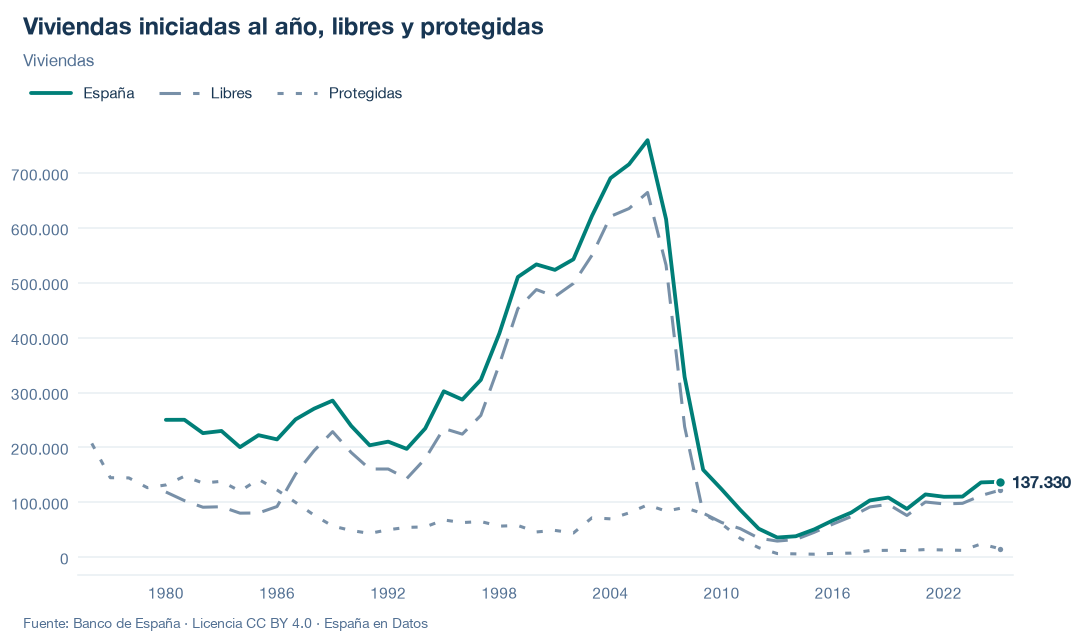

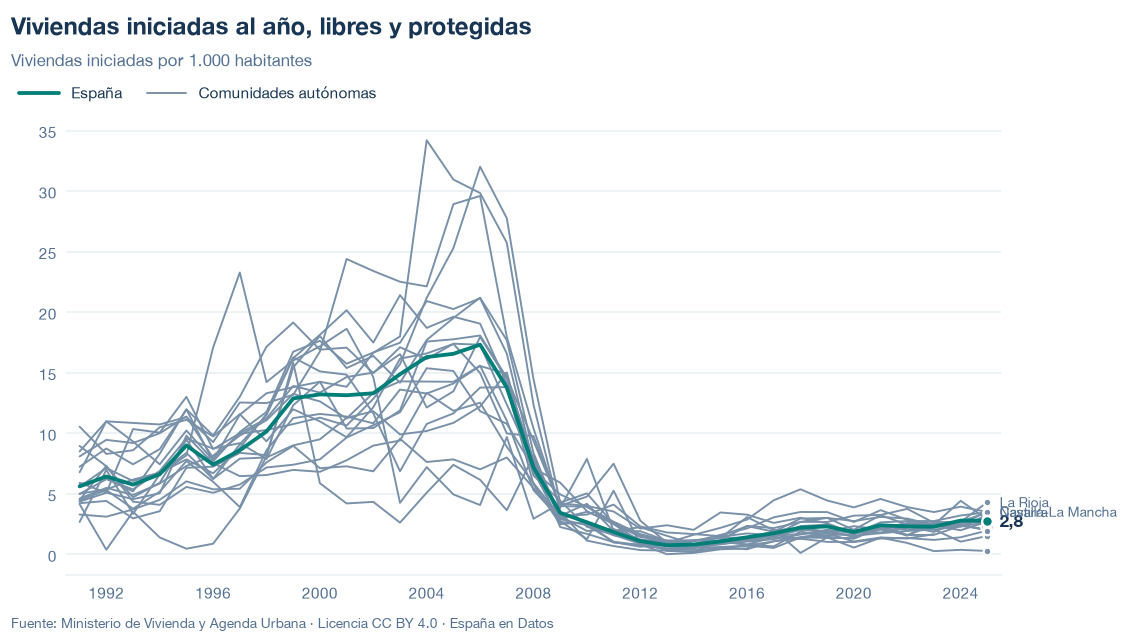

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, desglose=DESGLOSE, ccaa=vista_ccaa,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)
estilos.mostrar(estilos.figura_ccaa(datos, titulo=TITULO))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    desglose=DESGLOSE, ccaa=vista_ccaa, path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/viviendas-iniciadas.json y data/viviendas-iniciadas.csv


## 6. Fuentes, notas y licencia

- Banco de España, Boletín Estadístico, series `D_1KB02000` (total), `D_1KB02100` (libres) y `D_1KB02200` (protegidas), con datos del Ministerio de Vivienda y Agenda Urbana.
- Vista por comunidades: Ministerio de Vivienda y Agenda Urbana, Boletín estadístico online, tablas 3.1 (`32200500`) y 1.3 (`31303000`); INE, Estadística Continua de Población, tabla 56940.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.